# 04 · Log-mel CNN

## Does a small CNN on log-mel spectrograms beat tuned logistic regression?

This notebook scores a log-mel CNN under speaker-grouped CV and checks whether
averaging three training seeds stabilises the fold score (H24–H25).

**Inherits:** waveform loader and speaker split from `shared/`.
**Data:** 1,080 development clips.
**Runtime:** seconds with saved predictions; hours with `RUN_HEAVY = True`
(mel cache + CNN training + Grad-CAM; needs audio and preferably a GPU).
**Writes:** `outputs/preds/cnn_*.csv`, `preds/seeds/`, `tables/cnn_seed_summary.csv`,
figure F12.


In [1]:
# Setup: shared helpers, paths, and the switch for heavy steps.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
)

HERE = Path.cwd()
SHARED = next(p / "shared" for p in [HERE, *HERE.parents]
              if (p / "shared" / "audio_utils.py").exists())
sys.path.insert(0, str(SHARED))

import audio_utils as U
import cv_harness as H
import speaker_split as S

RUN_HEAVY = False  # True rebuilds from audio / features (minutes to hours)

SUB = U.submission_root()
OUT = SUB / "Modelling" / "outputs"
TABLES, FIGS, PREDS = OUT / "tables", OUT / "figures", OUT / "preds"
for d in (TABLES, FIGS, PREDS):
    d.mkdir(parents=True, exist_ok=True)
H.configure_paths(preds_dir=PREDS, tuning_log=TABLES / "tuning_log.csv")

EMOS = list(U.EMOTION_ORDER)
PCOLS = [f"p_{e}" for e in EMOS]
SUMMARY = []


def record(h, claim, verdict, evidence, decision):
    """Store one hypothesis result and print its verdict."""
    SUMMARY.append({
        "H": h, "hypothesis": claim, "verdict": verdict,
        "evidence": evidence, "so we": decision,
    })
    print(f"\n{h} · {claim}\n    verdict: {verdict.upper()}")


print(f"RUN_HEAVY={RUN_HEAVY}  preds={PREDS.relative_to(SUB)}")


RUN_HEAVY=False  preds=Modelling/outputs/preds


In [2]:
# Shared scoring helpers used by the live-compute path.
import re

TIERS = [
    (r"^logreg$", "M1", 1), (r"^svc$", "M1", 2), (r"^rf$", "M1", 3),
    (r"^gbm$", "M1", 4),
    (r"^logreg-(noweight|oversample|g\d)$", "M1a", 9),
    (r"-spkz$", "E4", 9),
    (r"^(wav2vec2|hubert|wavlm)$", "M3", 5),
    (r"^cnn$", "M2", 6), (r"^fusion", "M4", 7),
]
CANDIDATE_TIERS = {"M1", "M2", "M3", "M4"}


def tier_of(model: str):
    """Return (tier, simplicity_rank) for a model name."""
    for pat, tier, rank in TIERS:
        if re.search(pat, model):
            return tier, rank
    return "other", 99


def fold_metrics(df: pd.DataFrame) -> dict:
    """Accuracy, macro-F1, balanced accuracy and top-2 from one fold CSV."""
    yt, yp = df["true_emotion"].values, df["pred_emotion"].values
    out = {
        "accuracy": accuracy_score(yt, yp),
        "macro_f1": f1_score(
            yt, yp, average="macro", labels=EMOS, zero_division=0),
        "balanced_acc": balanced_accuracy_score(yt, yp),
        "top2_acc": float("nan"),
    }
    if all(c in df.columns for c in PCOLS):
        P = df[PCOLS].values
        top2 = np.argsort(-P, axis=1)[:, :2]
        truth = np.array([EMOS.index(e) for e in yt])
        out["top2_acc"] = float(
            np.mean([truth[i] in top2[i] for i in range(len(yt))]))
    return out


def fold_scores(model: str, split: str = "grouped") -> list[float]:
    """Macro-F1 of each fold for one model and split type."""
    return [
        fold_metrics(pd.read_csv(
            PREDS / f"{model}_{split}_fold{k}.csv"))["macro_f1"]
        for k in range(6)
    ]


def assert_close_frame(a: pd.DataFrame, b: pd.DataFrame, name: str,
                       atol: float = 1e-4):
    """Assert two numeric frames match within atol after rounding."""
    assert list(a.columns) == list(b.columns), f"{name} columns differ"
    assert len(a) == len(b), f"{name} row count differs"
    for c in a.columns:
        if pd.api.types.is_numeric_dtype(a[c]):
            aa, bb = a[c].astype(float).values, b[c].astype(float).values
            if not np.allclose(aa, bb, equal_nan=True, atol=atol):
                raise AssertionError(
                    f"{name}.{c} drifted: max "
                    f"{np.nanmax(np.abs(aa - bb)):.6g}")
        else:
            if not (a[c].astype(str).values == b[c].astype(str).values).all():
                raise AssertionError(f"{name}.{c} string values differ")
    print(f"[ok] live {name} matches saved file")


In [3]:
# Live: rebuild the 3-seed ensemble from preds/seeds and assert vs cnn_*.csv.
SEED_DIR = PREDS / "seeds"
EMOS_L = EMOS


def rebuild_cnn_ensemble(split: str, fold: int) -> pd.DataFrame:
    """Average class probabilities across seeds 0,1,2 for one fold."""
    parts = [
        pd.read_csv(SEED_DIR / f"cnn-s{s}_{split}_fold{fold}.csv")
        for s in (0, 1, 2)
    ]
    out = parts[0][["filepath", "true_emotion"]].copy()
    P = np.mean([p[PCOLS].values for p in parts], axis=0)
    out[PCOLS] = P
    out["pred_emotion"] = np.array(EMOS_L)[P.argmax(axis=1)]
    out["pred_confidence"] = P.max(axis=1)
    return out


seed_rows = []
for split in ("grouped", "random"):
    for fold in range(6):
        ens = rebuild_cnn_ensemble(split, fold)
        ref = pd.read_csv(PREDS / f"cnn_{split}_fold{fold}.csv")
        assert (ens["filepath"].values == ref["filepath"].values).all()
        # Probabilities match within float noise of the mean.
        assert np.allclose(
            ens[PCOLS].values, ref[PCOLS].values, atol=1e-4)
        assert (ens["pred_emotion"].values == ref["pred_emotion"].values).all()
        for s in (0, 1, 2):
            sdf = pd.read_csv(SEED_DIR / f"cnn-s{s}_{split}_fold{fold}.csv")
            seed_rows.append({
                "model": f"cnn-s{s}", "split_type": split, "fold": fold,
                "macro_f1": fold_metrics(sdf)["macro_f1"],
            })
        seed_rows.append({
            "model": "cnn", "split_type": split, "fold": fold,
            "macro_f1": fold_metrics(ref)["macro_f1"],
        })
print("[ok] 3-seed ensemble matches cnn_{grouped,random}_fold*.csv")

seed_df = pd.DataFrame(seed_rows)
live_summary = (
    seed_df.groupby(["model", "split_type"])["macro_f1"]
    .agg(["mean", lambda x: x.std(ddof=1), "count"])
    .reset_index()
)
live_summary.columns = [
    "model", "split_type", "macro_f1_mean",
    "macro_f1_sd_across_folds", "n_folds",
]
live_summary = live_summary.round(4)
saved_summary = pd.read_csv(TABLES / "cnn_seed_summary.csv")
# Saved may use model as index name depending on write path.
if "model" not in saved_summary.columns:
    saved_summary = saved_summary.rename(
        columns={saved_summary.columns[0]: "model"})
# Align columns for compare
# Saved table lists per-seed rows only (not the ensemble).
seed_only = live_summary[live_summary["model"].str.startswith("cnn-s")]
m = seed_only.merge(
    saved_summary, on=["model", "split_type"], suffixes=("_l", "_s"))
assert len(m) == len(saved_summary), (len(m), len(saved_summary))
for col in ["macro_f1_mean", "macro_f1_sd_across_folds"]:
    assert np.allclose(m[f"{col}_l"], m[f"{col}_s"], atol=1e-4), col
print("[ok] cnn_seed_summary.csv matches live seed scores")

cmp = pd.read_csv(TABLES / "model_comparison.csv")
elig = cmp[cmp["tier"].isin(CANDIDATE_TIERS)].copy()


[ok] 3-seed ensemble matches cnn_{grouped,random}_fold*.csv
[ok] cnn_seed_summary.csv matches live seed scores


### H24 · A log-mel CNN beats tuned logistic regression on speaker-grouped CV

**Why it matters:** if the CNN does not clear logistic regression, it is a contrast rung (Grad-CAM), not the accuracy route.

In [4]:
# H24: cnn vs logreg on grouped macro-F1.
m = elig.set_index("model")
cnn = float(m.loc["cnn", "grouped_macro_f1_mean"])
logreg = float(m.loc["logreg", "grouped_macro_f1_mean"])
print(f"cnn={cnn:.4f}  logreg={logreg:.4f}")
verdict = "supported" if cnn > logreg else "not supported"
record(
    "H24",
    "A log-mel CNN beats tuned logistic regression on speaker-grouped CV",
    verdict,
    f"cnn {cnn:.4f} vs logreg {logreg:.4f}",
    "keep the CNN as a Grad-CAM contrast, not the headline model",
)


cnn=0.4327  logreg=0.5169

H24 · A log-mel CNN beats tuned logistic regression on speaker-grouped CV
    verdict: NOT SUPPORTED


**Verdict: not supported. [EVIDENCE]** The CNN reaches 0.4327 against 0.5169 for logistic regression. Learning directly from spectrograms, with 1,080 development clips, falls short of the hand-built features.

**So we** keep the CNN on the ladder as the contrast rung (its Grad-CAM maps show where it listens), not as the accuracy route. The next notebook tests encoders pre-trained on other speech.

### H25 · Averaging three training seeds stabilises the CNN fold score

**Why it matters:** a single training seed can look lucky or unlucky; if averaging seeds does not narrow the spread, a single CNN score should be read with that spread in mind.

In [5]:
# H25: fold-to-fold SD of ensemble vs single seeds; report gaps.
# Use grouped split (the real estimate).
g_ens = seed_df[(seed_df.model == "cnn") & (seed_df.split_type == "grouped")]
ens_sd = float(g_ens["macro_f1"].std(ddof=1))
seed_sds = []
gaps = []
for fold in range(6):
    ens_f = float(g_ens.loc[g_ens.fold == fold, "macro_f1"].iloc[0])
    seed_f = [
        float(seed_df.loc[
            (seed_df.model == f"cnn-s{s}")
            & (seed_df.split_type == "grouped")
            & (seed_df.fold == fold), "macro_f1"].iloc[0])
        for s in (0, 1, 2)
    ]
    mean_seed = float(np.mean(seed_f))
    gap = ens_f - mean_seed
    gaps.append(gap)
    print(f"fold {fold}: ens={ens_f:.4f}  mean_seed={mean_seed:.4f}  "
          f"gap={gap:+.4f}")
for s in (0, 1, 2):
    sd_s = float(seed_df[
        (seed_df.model == f"cnn-s{s}") & (seed_df.split_type == "grouped")
    ]["macro_f1"].std(ddof=1))
    seed_sds.append(sd_s)
    print(f"cnn-s{s} fold-SD={sd_s:.5f}")
print(f"ensemble fold-SD={ens_sd:.5f}")
mean_seed_sd = float(np.mean(seed_sds))
mean_gap = float(np.mean(gaps))
print(f"mean single-seed fold-SD={mean_seed_sd:.5f}")
print(f"mean ensemble-minus-mean-seed gap={mean_gap:+.5f}")
n_up = sum(gp > 0 for gp in gaps)
print(f"folds where the ensemble beats its seed mean: {n_up} of {len(gaps)}")
# Supported if ensemble fold-SD is <= mean of single-seed fold-SDs.
verdict = "supported" if ens_sd <= mean_seed_sd else "not supported"
# Partly supported if ens SD is lower than at least 2 of 3 seeds.
if verdict == "not supported" and sum(ens_sd <= s for s in seed_sds) >= 2:
    verdict = "partly supported"
decision = (
    "report the three-seed ensemble as the CNN rung "
    f"(mean gain per fold {mean_gap:+.5f})"
)
record(
    "H25",
    "Averaging three training seeds stabilises the CNN fold score",
    verdict,
    (f"ens_sd={ens_sd:.5f}; mean_seed_sd={mean_seed_sd:.5f}; "
     f"mean_gap={mean_gap:+.5f}; "
     f"gaps={', '.join(f'{g:+.4f}' for g in gaps)}"),
    decision,
)


fold 0: ens=0.4595  mean_seed=0.4525  gap=+0.0070
fold 1: ens=0.4615  mean_seed=0.3821  gap=+0.0794
fold 2: ens=0.3657  mean_seed=0.3852  gap=-0.0195
fold 3: ens=0.3431  mean_seed=0.3380  gap=+0.0051
fold 4: ens=0.4575  mean_seed=0.4497  gap=+0.0078
fold 5: ens=0.5091  mean_seed=0.4271  gap=+0.0820
cnn-s0 fold-SD=0.04676
cnn-s1 fold-SD=0.04933
cnn-s2 fold-SD=0.09598
ensemble fold-SD=0.06404
mean single-seed fold-SD=0.06402
mean ensemble-minus-mean-seed gap=+0.02696
folds where the ensemble beats its seed mean: 5 of 6

H25 · Averaging three training seeds stabilises the CNN fold score
    verdict: NOT SUPPORTED


**Verdict: not supported. [EVIDENCE]** The fold-to-fold spread of the three-seed ensemble (sd 0.06404) is no narrower than that of a single seed on average (0.06402). Averaging does raise the score: the ensemble beats the mean of its seeds on 5 of 6 folds, by +0.02696 on average.

**So we** report the three-seed ensemble as the CNN rung for its higher mean, not for stability; its spread stays as wide as a single seed's.

### CNN definition, training and Grad-CAM (RUN_HEAVY)

The cells below contain the real model and training loop ported from the modelling archive. With `RUN_HEAVY = False` they are not executed; the code remains visible for review.

In [6]:
# Model definition and training helpers (always visible).
# Faithful port of R2/train_cnn.py: torch STFT log-mel, SmallCNN, train_one.
import warnings

SR = U.TARGET_RATE
N_FFT, HOP, N_MELS = 400, 160, 64
MAX_EPOCHS, PATIENCE, BATCH, LR, WD = 60, 12, 32, 1e-3, 1e-2

_MEL = None


def mel_fb():
    """Cached mel filterbank (N_MELS x N_FFT/2+1)."""
    global _MEL
    if _MEL is None:
        import librosa
        import torch
        _MEL = torch.tensor(
            librosa.filters.mel(
                sr=SR, n_fft=N_FFT, n_mels=N_MELS, fmax=SR // 2),
            dtype=torch.float32,
        )
    return _MEL


def logmel(w):
    """(B, T) waveform -> (B, 64, frames) log-mel via torch STFT."""
    import torch
    spec = torch.stft(
        w, N_FFT, HOP, N_FFT, torch.hann_window(N_FFT),
        return_complex=True,
    ).abs() ** 2
    return torch.log(mel_fb() @ spec + 1e-6)


def augment_wave(w, rng):
    """Circular time shift +/-0.25 s and light Gaussian noise."""
    import torch
    w = w.clone()
    for i in range(w.shape[0]):
        w[i] = torch.roll(
            w[i], int(rng.integers(-SR // 4, SR // 4 + 1)))
        rms = w[i].pow(2).mean().sqrt()
        if rms > 0:
            snr_db = rng.uniform(20, 40)
            w[i] += torch.randn_like(w[i]) * rms / (10 ** (snr_db / 20))
    return w


def spec_augment(m, rng):
    """Two frequency masks (<=8 bins) and two time masks (<=25 frames)."""
    import torch
    m = m.clone()
    B, Fb, T = m.shape
    for i in range(B):
        for _ in range(2):
            f = int(rng.integers(0, 9))
            f0 = int(rng.integers(0, Fb - f + 1))
            m[i, f0:f0 + f, :] = 0.0
            t = int(rng.integers(0, 26))
            t0 = int(rng.integers(0, T - t + 1))
            m[i, :, t0:t0 + t] = 0.0
    return m


try:
    import torch
    import torch.nn as nn

    class SmallCNN(nn.Module):
        """Four-block log-mel CNN with global mean pool and linear head."""

        def __init__(self, n_classes=8, chans=(16, 32, 64, 128),
                     dropout=0.3):
            super().__init__()
            layers, c_in = [], 1
            for c in chans:
                layers += [
                    nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c),
                    nn.ReLU(), nn.MaxPool2d(2),
                ]
                c_in = c
            self.features = nn.Sequential(*layers)
            self.head = nn.Sequential(
                nn.Dropout(dropout), nn.Linear(c_in, n_classes))

        def forward(self, x):
            z = self.features(x.unsqueeze(1))
            return self.head(z.mean(dim=(2, 3)))

    print("SmallCNN defined (torch available)")
except ImportError:
    SmallCNN = None  # type: ignore
    print("torch not installed: CNN training cell will no-op unless RUN_HEAVY")


SmallCNN defined (torch available)


[cache hit] CNN preds / seeds / F12
[cache hit] Modelling/outputs/figures/F12_gradcam.png


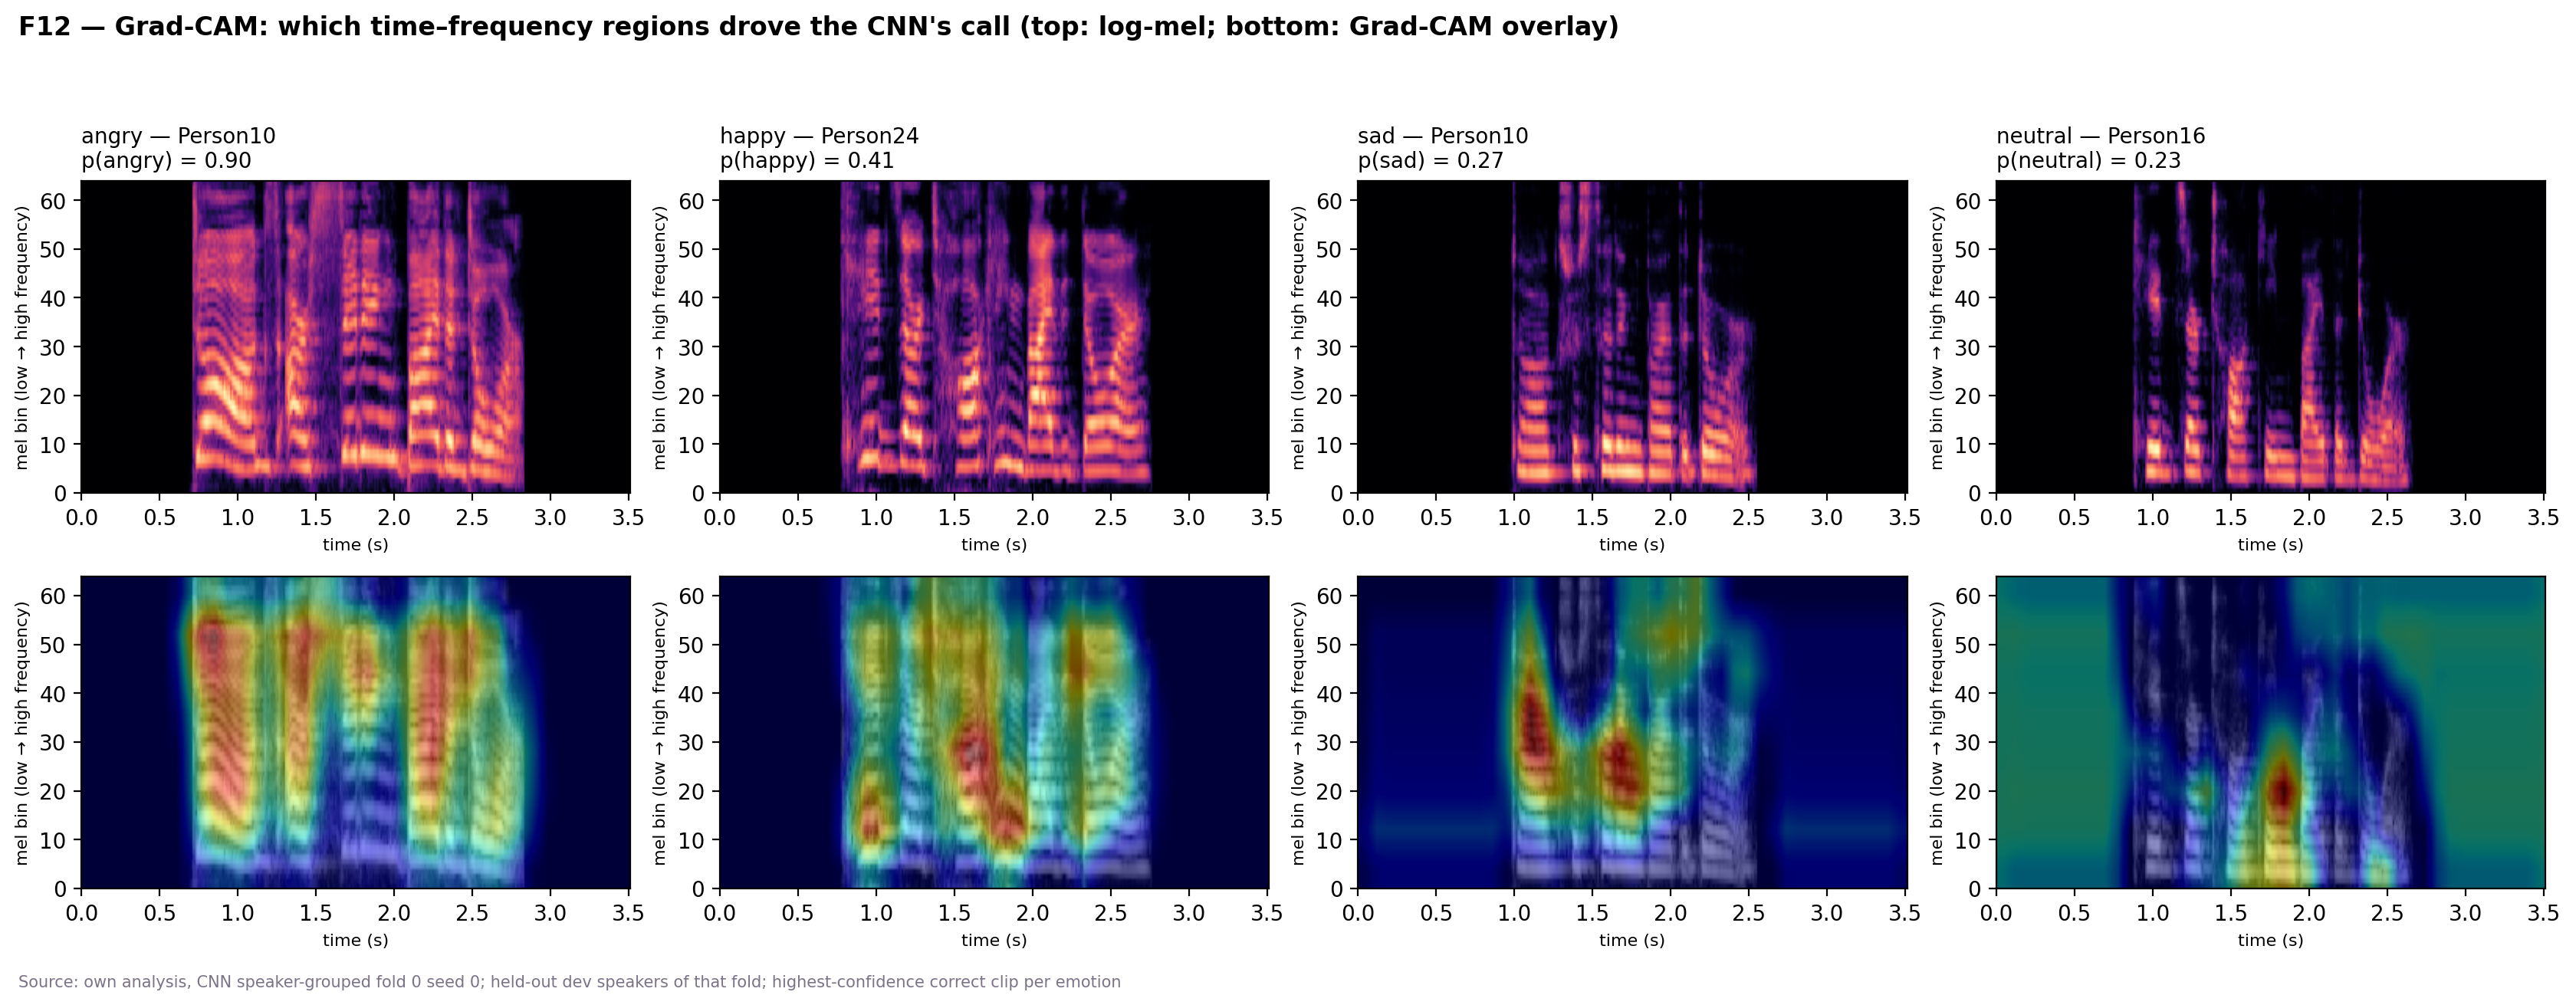

In [7]:
# RUN_HEAVY: waveform log-mel CNN CV (both splits, 3 seeds) + Grad-CAM.
# Port of R2/train_cnn.py and R3/error_analysis.f12_gradcam.
from IPython.display import Image, display

SEED_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = SUB / "cache" / "cnn_models"
F12_PATH = FIGS / "F12_gradcam.png"

if RUN_HEAVY:
    if SmallCNN is None:
        raise ImportError("torch required for RUN_HEAVY CNN rebuild")
    import torch
    import torch.nn as nn
    from sklearn.model_selection import GroupKFold, StratifiedShuffleSplit
    from sklearn.metrics import f1_score as f1s

    torch.manual_seed(42)
    np.random.seed(42)
    if hasattr(torch, "use_deterministic_algorithms"):
        try:
            torch.use_deterministic_algorithms(True, warn_only=True)
        except Exception:
            warnings.warn("deterministic algorithms not fully available")

    index = U.load_index()
    msk = S.dev_mask(index)
    S.assert_no_test_speakers(index.loc[msk, "filepath"], "CNN heavy")
    y_str = index.loc[msk, "emotion"].values
    y = np.array([EMOS.index(e) for e in y_str])
    g = index.loc[msk, "speaker"].astype(int).values
    fps = index.loc[msk, "filepath"].values
    W_all = U.load_waveform_cache()
    W = torch.tensor(W_all[msk])

    def _predict(model, M, device, bs=128):
        model.eval()
        out = []
        with torch.no_grad():
            for i in range(0, len(M), bs):
                out.append(torch.softmax(
                    model(M[i:i + bs].to(device)), dim=1).cpu())
        return torch.cat(out).numpy()

    def train_one(Wtr, ytr, Wes, yes, seed, device, verbose=False):
        """Train on waveforms; early-stop on inner val macro-F1."""
        torch.manual_seed(seed)
        rng = np.random.default_rng(seed)
        Mtr_clean = logmel(Wtr)
        mu = Mtr_clean.mean(dim=(0, 2), keepdim=True)[0]
        sd = Mtr_clean.std(dim=(0, 2), keepdim=True)[0] + 1e-5
        Mes = (logmel(Wes) - mu) / sd
        counts = np.bincount(ytr, minlength=len(EMOS))
        cw = torch.tensor(
            len(ytr) / (len(EMOS) * np.maximum(counts, 1)),
            dtype=torch.float32,
        )
        model = SmallCNN().to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            opt, T_max=MAX_EPOCHS)
        lossf = nn.CrossEntropyLoss(weight=cw.to(device))
        ytr_t = torch.tensor(ytr)
        best = (-1.0, 0, None)
        ep = 0
        for ep in range(MAX_EPOCHS):
            model.train()
            perm = rng.permutation(len(ytr))
            for b in range(0, len(perm), BATCH):
                idx = perm[b:b + BATCH]
                if len(idx) < 2:
                    continue
                m = (logmel(augment_wave(Wtr[idx], rng)) - mu) / sd
                m = spec_augment(m, rng)
                opt.zero_grad()
                loss = lossf(
                    model(m.to(device)), ytr_t[idx].to(device))
                loss.backward()
                opt.step()
            sched.step()
            f1 = f1s(
                yes, _predict(model, Mes, device).argmax(1),
                average="macro", labels=range(len(EMOS)), zero_division=0)
            if f1 > best[0]:
                best = (f1, ep, {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()})
            if ep - best[1] >= PATIENCE:
                break
        model.load_state_dict(best[2])
        info = {
            "inner_macro_f1": best[0],
            "best_epoch": best[1],
            "epochs_run": ep + 1,
        }
        return model, (mu, sd), info

    def inner_split(split_type, y_sub, g_sub, seed):
        if split_type == "grouped":
            tr, es = next(GroupKFold(5).split(
                np.zeros(len(y_sub)), y_sub, g_sub))
            assert not set(g_sub[tr]) & set(g_sub[es])
        else:
            tr, es = next(StratifiedShuffleSplit(
                1, test_size=0.2, random_state=seed
            ).split(np.zeros(len(y_sub)), y_sub))
        return tr, es

    device = "mps" if torch.backends.mps.is_available() else (
        "cuda" if torch.cuda.is_available() else "cpu")
    print("CNN device:", device)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    cam_ck = None
    for st in ("grouped", "random"):
        for k, (tr, va) in enumerate(
                S.outer_splits(st, np.zeros(len(y)), y_str, g)):
            probs = []
            itr, ies = inner_split(st, y[tr], g[tr], H.SEED + k)
            itr, ies = tr[itr], tr[ies]
            Mva_raw = logmel(W[va])
            for s in (0, 1, 2):
                model, (mu, sd), info = train_one(
                    W[itr], y[itr], W[ies], y[ies], s, device)
                p = _predict(model, (Mva_raw - mu) / sd, device)
                probs.append(p)
                H.save_preds(
                    SEED_DIR / f"cnn-s{s}_{st}_fold{k}.csv",
                    fps[va], y_str[va], p, EMOS)
                torch.save(
                    {"state_dict": model.state_dict(), "mu": mu, "sd": sd,
                     "info": info},
                    MODEL_DIR / f"{st}_fold{k}_s{s}.pt")
                f1_out = f1s(
                    y[va], p.argmax(1), average="macro",
                    labels=range(8), zero_division=0)
                print(
                    f"  cnn {st:<7} fold{k} seed{s}  "
                    f"macro-F1 {f1_out:.4f}  "
                    f"best ep {info['best_epoch']}",
                    flush=True)
                if st == "grouped" and k == 0 and s == 0:
                    cam_ck = {
                        "state_dict": {
                            kk: vv.detach().cpu().clone()
                            for kk, vv in model.state_dict().items()},
                        "mu": mu.detach().cpu().clone(),
                        "sd": sd.detach().cpu().clone(),
                    }
            pm = np.mean(probs, axis=0)
            H.save_preds(
                PREDS / f"cnn_{st}_fold{k}.csv",
                fps[va], y_str[va], pm, EMOS)
    print("[RUN_HEAVY] CNN preds rewritten")

    # Grad-CAM: fold 0 seed 0, same logmel as training (f12_gradcam).
    fold, seed = 0, 0
    _, va = S.outer_splits(
        "grouped", np.zeros(len(y)), y_str, g)[fold]
    if cam_ck is None:
        ck = torch.load(
            MODEL_DIR / f"grouped_fold{fold}_s{seed}.pt",
            weights_only=False)
    else:
        ck = cam_ck
    model = SmallCNN()
    model.load_state_dict(ck["state_dict"])
    model.eval()
    target_layer = model.features[-3]
    acts, grads = {}, {}
    target_layer.register_forward_hook(
        lambda m, i, o: acts.__setitem__("a", o))
    target_layer.register_full_backward_hook(
        lambda m, gi, go: grads.__setitem__("g", go[0]))
    Mraw = logmel(W[va])
    M = (Mraw - ck["mu"]) / ck["sd"]
    with torch.no_grad():
        P = torch.softmax(model(M), 1).numpy()
    emotions = ("angry", "happy", "sad", "neutral")
    fig, axes = plt.subplots(2, len(emotions), figsize=(4.2 * 4, 6.5))
    for c, e in enumerate(emotions):
        ci = EMOS.index(e)
        ok = np.flatnonzero((y[va] == ci) & (P.argmax(1) == ci))
        if ok.size == 0:
            axes[0, c].set_title(f"{e}: no correct clip in fold {fold}")
            continue
        i = ok[np.argmax(P[ok, ci])]
        x = M[i:i + 1].clone().requires_grad_(True)
        model.zero_grad()
        out = model(x)
        out[0, ci].backward()
        a, gr = acts["a"][0], grads["g"][0]
        cam = torch.relu(
            (gr.mean(dim=(1, 2), keepdim=True) * a).sum(0)).detach()
        cam = torch.nn.functional.interpolate(
            cam[None, None], size=M.shape[1:], mode="bilinear"
        )[0, 0].numpy()
        cam = cam / (cam.max() + 1e-8)
        ext = [0, M.shape[2] * HOP / SR, 0, N_MELS]
        axes[0, c].imshow(
            Mraw[i].numpy(), origin="lower", aspect="auto",
            cmap="magma", extent=ext)
        spk = Path(fps[va][i]).parent.name
        axes[0, c].set_title(
            f"{e} - {spk}\np({e}) = {P[i, ci]:.2f}",
            fontsize=10, loc="left")
        axes[1, c].imshow(
            Mraw[i].numpy(), origin="lower", aspect="auto",
            cmap="gray", extent=ext)
        axes[1, c].imshow(
            cam, origin="lower", aspect="auto", cmap="jet",
            alpha=0.45, extent=ext)
        for r in (0, 1):
            axes[r, c].set_xlabel("time (s)", fontsize=8)
            axes[r, c].set_ylabel(
                "mel bin (low -> high frequency)", fontsize=8)
    fig.suptitle(
        "F12 - Grad-CAM: which time-frequency regions drove the "
        "CNN's call (top: log-mel; bottom: Grad-CAM overlay)",
        fontsize=12, fontweight="600", x=0.01, ha="left")
    fig.text(
        0.01, 0.005,
        f"Source: own analysis, CNN speaker-grouped fold {fold} "
        f"seed {seed}; held-out dev speakers of that fold; "
        "highest-confidence correct clip per emotion",
        fontsize=7.5, color="#7C7389")
    fig.tight_layout(rect=[0, 0.02, 1, 0.94])
    U.save_figure(fig, "F12_gradcam.png", out_dir=FIGS)
    plt.show()
    print("[RUN_HEAVY] wrote F12_gradcam.png")
else:
    print("[cache hit] CNN preds / seeds / F12")
    if F12_PATH.exists():
        print(f"[cache hit] {F12_PATH.relative_to(SUB)}")
        display(Image(filename=str(F12_PATH)))


In [8]:
# Summary table for this notebook.
summary = pd.DataFrame(SUMMARY).set_index("H")
display(summary)
summary.to_csv(TABLES / "summary_04.csv")


,hypothesis,verdict,evidence,so we
H,,,,
H24,A log-mel CNN beats tuned logistic regression ...,not supported,cnn 0.4327 vs logreg 0.5169,"keep the CNN as a Grad-CAM contrast, not the h..."
H25,Averaging three training seeds stabilises the ...,not supported,ens_sd=0.06404; mean_seed_sd=0.06402; mean_gap...,report the three-seed ensemble as the CNN rung...


**Hands on:** CNN fold predictions. Next notebook scores frozen speech encoders and fusion.